# Ajuste polinomial y sobreajuste

*Pattern Recognition and Machine Learning*, de Christopher Bishop, abre con un ejemplo pequeño: diez puntos tomados de una sinusoide con ruido, y polinomios de distintos grados para ajustarlos. Con él presenta casi todas las ideas de las que depende el machine learning: error de entrenamiento y de prueba, **sobreajuste**, el efecto de tener más datos, la **regularización** y cómo elegir un modelo sin mirar los datos de prueba. Este notebook reproduce la sección 1.1 de Bishop con PyTorch.

**Contenido**

1. Preparación
2. Los datos
3. Ajustar un polinomio
4. Error de entrenamiento y error de prueba
5. Los coeficientes explotan
6. Más datos
7. Regularización
8. Elegir λ sin mirar la prueba: validación cruzada
9. La misma solución con un optimizador de PyTorch
10. Resumen y ejercicios

## 1. Preparación

Usamos `float64`: un polinomio de grado 9 con entradas entre 0 y 1 produce matrices mal condicionadas, y en `float32` los errores de redondeo se notan.

In [1]:
import math

import torch
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. Los datos

Como en Bishop, la función real es $\sin(2\pi x)$ en $[0, 1]$, y cada observación tiene ruido gaussiano de desviación 0.3:

$$t = \sin(2\pi x) + \varepsilon \qquad \varepsilon \sim \mathcal{N}(0, 0.3^2)$$

El conjunto de entrenamiento son 10 puntos con $x$ equiespaciado. El de prueba son 100 puntos con $x$ al azar, generados igual pero con otro ruido.

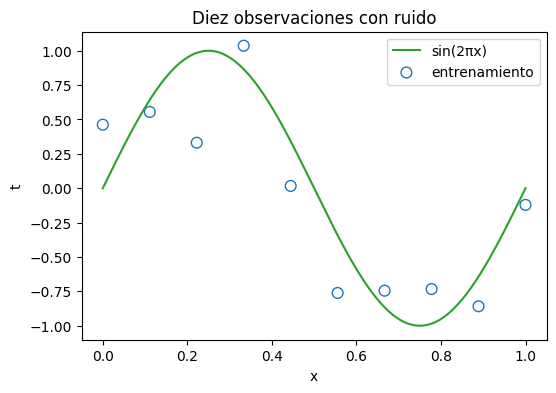

In [2]:
def generar(n, semilla, equiespaciado=True, ruido=0.3):
    generador = torch.Generator().manual_seed(semilla)
    x = torch.linspace(0, 1, n) if equiespaciado else torch.rand(n, generator=generador)
    t = torch.sin(2 * math.pi * x) + ruido * torch.randn(n, generator=generador)
    return x, t


x, t = generar(10, semilla=0)
x_prueba, t_prueba = generar(100, semilla=1, equiespaciado=False)
x_fino = torch.linspace(0, 1, 500)

plt.figure(figsize=(6, 4))
plt.plot(x_fino, torch.sin(2 * math.pi * x_fino), color="tab:green", label="sin(2πx)")
plt.scatter(x, t, facecolors="none", edgecolors="tab:blue", s=60, label="entrenamiento")
plt.xlabel("x")
plt.ylabel("t")
plt.title("Diez observaciones con ruido")
plt.legend()
plt.show()

## 3. Ajustar un polinomio

El modelo es un polinomio de grado $M$:

$$y(x, w) = w_0 + w_1 x + w_2 x^2 + \dots + w_M x^M = \sum_{j=0}^{M} w_j x^j$$

Es no lineal en $x$ pero **lineal en los coeficientes** $w$. Si se arma la matriz $\Phi$ cuya fila $n$ es $(1, x_n, x_n^2, \dots, x_n^M)$, las predicciones son $\Phi w$, y ajustar el polinomio es una regresión lineal con $M + 1$ características.

Bishop minimiza la suma de errores al cuadrado $E(w) = \frac{1}{2}\sum_n \big(y(x_n, w) - t_n\big)^2$. Su mínimo tiene forma cerrada, las **ecuaciones normales** de `03-optimalidad`: $\Phi^\top \Phi \, w = \Phi^\top t$. Para resolverlas usamos `torch.linalg.lstsq`, que no forma $\Phi^\top\Phi$ explícitamente y es más estable.

Para comparar ajustes con distinto número de puntos, Bishop usa la raíz del error cuadrático medio, $E_{\text{RMS}} = \sqrt{2E(w)/N}$, que está en las mismas unidades que $t$.

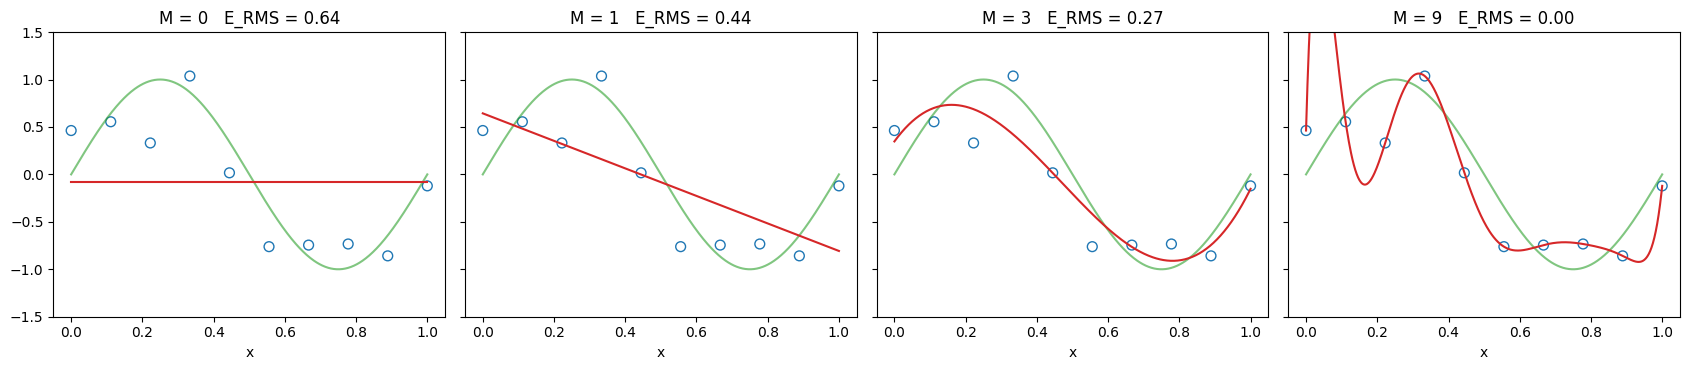

In [3]:
def caracteristicas(x, M):
    return x.unsqueeze(1) ** torch.arange(M + 1)        # [N, M+1]: columnas 1, x, x², ..., x^M


def ajustar(x, t, M):
    return torch.linalg.lstsq(caracteristicas(x, M), t.unsqueeze(1)).solution.squeeze(1)


def predecir(x, w):
    return caracteristicas(x, len(w) - 1) @ w


def e_rms(x, t, w):
    return (predecir(x, w) - t).pow(2).mean().sqrt().item()


fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for eje, M in zip(ejes, [0, 1, 3, 9]):
    w = ajustar(x, t, M)
    eje.plot(x_fino, torch.sin(2 * math.pi * x_fino), color="tab:green", alpha=0.6)
    eje.plot(x_fino, predecir(x_fino, w), color="tab:red")
    eje.scatter(x, t, facecolors="none", edgecolors="tab:blue", s=50)
    eje.set_ylim(-1.5, 1.5)
    eje.set_title(f"M = {M}   E_RMS = {e_rms(x, t, w):.2f}")
    eje.set_xlabel("x")
plt.tight_layout()
plt.show()

- **M = 0 y M = 1** son demasiado rígidos: una constante y una recta no pueden seguir una onda.
- **M = 3** sigue bien la forma de la sinusoide.
- **M = 9** pasa **exactamente** por los diez puntos ($E_{\text{RMS}} = 0$): con 10 coeficientes y 10 puntos siempre hay un polinomio que interpola. Pero entre los puntos oscila sin control y se aleja de la curva real.

## 4. Error de entrenamiento y error de prueba

Un error de entrenamiento de 0 no dice nada bueno del modelo de grado 9. Lo que importa es qué tan bien predice puntos **nuevos**. Medimos los dos errores para cada grado:

M = 0:  entrenamiento 0.637   prueba 0.810
M = 1:  entrenamiento 0.438   prueba 0.575
M = 2:  entrenamiento 0.425   prueba 0.576
M = 3:  entrenamiento 0.265   prueba 0.376
M = 4:  entrenamiento 0.262   prueba 0.383
M = 5:  entrenamiento 0.241   prueba 0.379
M = 6:  entrenamiento 0.220   prueba 0.389
M = 7:  entrenamiento 0.147   prueba 0.447
M = 8:  entrenamiento 0.036   prueba 0.504
M = 9:  entrenamiento 0.000   prueba 0.553


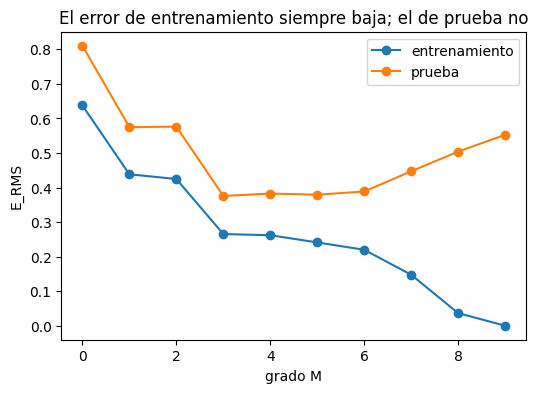

In [4]:
grados = list(range(10))
errores_entrenamiento, errores_prueba = [], []
for M in grados:
    w = ajustar(x, t, M)
    errores_entrenamiento.append(e_rms(x, t, w))
    errores_prueba.append(e_rms(x_prueba, t_prueba, w))
    print(f"M = {M}:  entrenamiento {errores_entrenamiento[-1]:.3f}   prueba {errores_prueba[-1]:.3f}")

plt.figure(figsize=(6, 4))
plt.plot(grados, errores_entrenamiento, "o-", label="entrenamiento")
plt.plot(grados, errores_prueba, "o-", label="prueba")
plt.xlabel("grado M")
plt.ylabel("E_RMS")
plt.title("El error de entrenamiento siempre baja; el de prueba no")
plt.legend()
plt.show()

El error de entrenamiento baja con cada grado que se agrega, hasta llegar a 0. Tiene que ser así: un polinomio de grado $M$ incluye a todos los de grado menor (basta poner los coeficientes extra en 0), así que el mejor ajuste no puede empeorar.

El error de prueba baja hasta $M = 3$ y después sube. Desde ahí, el modelo usa sus coeficientes extra para seguir el **ruido** de estos diez puntos en particular, y eso no se repite en datos nuevos. Eso es el **sobreajuste**: un modelo más flexible que lo que los datos alcanzan a determinar.

## 5. Los coeficientes explotan

La tabla 1.1 de Bishop muestra los coeficientes de cada ajuste. Reproducimos la idea:

In [5]:
coeficientes = {M: ajustar(x, t, M) for M in [0, 1, 3, 9]}

print("        " + "".join(f"{f'M = {M}':>14s}" for M in coeficientes))
for j in range(10):
    fila = ""
    for w in coeficientes.values():
        fila += f"{w[j].item():14.2f}" if j < len(w) else f"{'':14s}"
    print(f"w{j}      {fila}")

                 M = 0         M = 1         M = 3         M = 9
w0               -0.08          0.64          0.35          0.46
w1                             -1.45          5.17        131.77
w2                                          -19.42      -2801.75
w3                                           13.75      22753.59
w4                                                     -94962.31
w5                                                     228383.80
w6                                                    -330422.13
w7                                                     284742.84
w8                                                    -134947.77
w9                                                      27121.38


Con $M = 9$ los coeficientes llegan a cientos de miles, con signos alternados. El polinomio pasa por los puntos gracias a cancelaciones enormes entre términos, y por eso oscila tanto entre ellos: cualquier cambio pequeño en $x$ se amplifica. Los coeficientes grandes son el síntoma del sobreajuste, y la sección 7 los ataca directamente.

## 6. Más datos

El problema no es el grado 9 en sí, sino el grado 9 con **diez** puntos. Con más datos, el mismo modelo tiene menos libertad para seguir el ruido de cada uno:

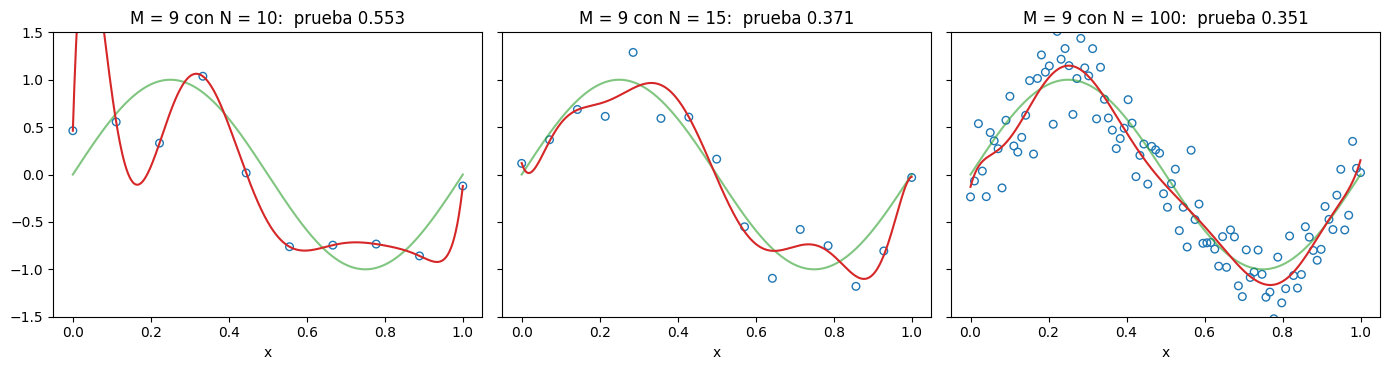

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for eje, n in zip(ejes, [10, 15, 100]):
    x_n, t_n = (x, t) if n == 10 else generar(n, semilla=2)
    w = ajustar(x_n, t_n, 9)
    eje.plot(x_fino, torch.sin(2 * math.pi * x_fino), color="tab:green", alpha=0.6)
    eje.plot(x_fino, predecir(x_fino, w), color="tab:red")
    eje.scatter(x_n, t_n, facecolors="none", edgecolors="tab:blue", s=30)
    eje.set_ylim(-1.5, 1.5)
    eje.set_title(f"M = 9 con N = {n}:  prueba {e_rms(x_prueba, t_prueba, w):.3f}")
    eje.set_xlabel("x")
plt.tight_layout()
plt.show()

Con 100 puntos, el polinomio de grado 9 queda pegado a la sinusoide y su error de prueba es menor que el de cualquier grado con 10 puntos. La regla práctica que menciona Bishop: el número de puntos debería ser varias veces el número de parámetros. Para las redes neuronales, con millones de parámetros, esta regla no se cumple al pie de la letra, pero la idea de fondo se mantiene: más datos permiten modelos más flexibles.

## 7. Regularización

Cuando no se pueden conseguir más datos, se puede castigar a los coeficientes grandes. Bishop agrega a la pérdida un término proporcional a $\lVert w \rVert^2$:

$$\tilde{E}(w) = \frac{1}{2}\sum_n \big(y(x_n, w) - t_n\big)^2 + \frac{\lambda}{2}\lVert w \rVert^2$$

Es la **regularización L2**, la misma que hace `weight_decay` en los optimizadores de PyTorch (`04-matematica-de-pytorch/04_optimizadores`, sección 3). En estadística se llama *ridge regression*. Derivando e igualando a 0, el mínimo también tiene forma cerrada:

$$(\Phi^\top\Phi + \lambda I)\, w = \Phi^\top t$$

Sumar $\lambda I$ además mejora el condicionamiento de la matriz: sus autovalores suben en $\lambda$, así que el más chico deja de estar cerca de 0.

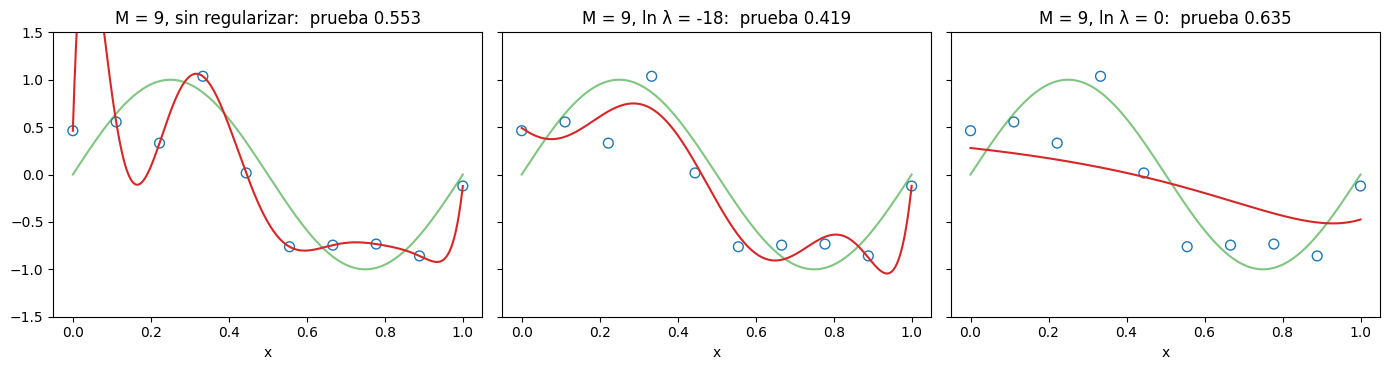

coeficiente más grande en valor absoluto:
  sin regularizar     330422.13
  ln λ =  -18            603.38
  ln λ =    0              0.45


In [7]:
def ajustar_regularizado(x, t, M, lam):
    Phi = caracteristicas(x, M)
    return torch.linalg.solve(Phi.T @ Phi + lam * torch.eye(M + 1), Phi.T @ t)


fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for eje, ln_lam in zip(ejes, [None, -18, 0]):
    w = ajustar(x, t, 9) if ln_lam is None else ajustar_regularizado(x, t, 9, math.exp(ln_lam))
    eje.plot(x_fino, torch.sin(2 * math.pi * x_fino), color="tab:green", alpha=0.6)
    eje.plot(x_fino, predecir(x_fino, w), color="tab:red")
    eje.scatter(x, t, facecolors="none", edgecolors="tab:blue", s=50)
    eje.set_ylim(-1.5, 1.5)
    nombre = "sin regularizar" if ln_lam is None else f"ln λ = {ln_lam}"
    eje.set_title(f"M = 9, {nombre}:  prueba {e_rms(x_prueba, t_prueba, w):.3f}")
    eje.set_xlabel("x")
plt.tight_layout()
plt.show()

print("coeficiente más grande en valor absoluto:")
print(f"  sin regularizar  {ajustar(x, t, 9).abs().max():12.2f}")
for ln_lam in [-18, 0]:
    print(f"  ln λ = {ln_lam:4d}      {ajustar_regularizado(x, t, 9, math.exp(ln_lam)).abs().max():12.2f}")

Con $\ln\lambda = -18$ (un λ de apenas $1.5 \times 10^{-8}$) las oscilaciones del polinomio de grado 9 se reducen mucho y la curva se acerca a la sinusoide, aunque todavía ondula un poco cerca de los extremos. Los coeficientes bajan de cientos de miles a cientos. Con $\ln\lambda = 0$ el castigo es demasiado fuerte: los coeficientes quedan tan chicos que el polinomio no alcanza a subir y bajar.

Barriendo λ se ve el mismo patrón que con el grado:

menor error de prueba: 0.374 con ln λ = -12
comparar con M = 3 sin regularizar: 0.376


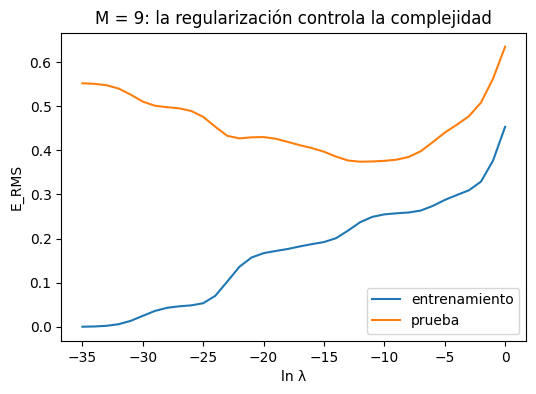

In [8]:
ln_lambdas = torch.arange(-35, 1, 1.0)
entrenamiento_l, prueba_l = [], []
for ln_lam in ln_lambdas:
    w = ajustar_regularizado(x, t, 9, math.exp(ln_lam))
    entrenamiento_l.append(e_rms(x, t, w))
    prueba_l.append(e_rms(x_prueba, t_prueba, w))

mejor = int(torch.tensor(prueba_l).argmin())
print(f"menor error de prueba: {prueba_l[mejor]:.3f} con ln λ = {ln_lambdas[mejor]:.0f}")
print(f"comparar con M = 3 sin regularizar: {errores_prueba[3]:.3f}")

plt.figure(figsize=(6, 4))
plt.plot(ln_lambdas, entrenamiento_l, label="entrenamiento")
plt.plot(ln_lambdas, prueba_l, label="prueba")
plt.xlabel("ln λ")
plt.ylabel("E_RMS")
plt.title("M = 9: la regularización controla la complejidad")
plt.legend()
plt.show()

Con λ chico, el modelo sobreajusta (error de entrenamiento casi 0, error de prueba alto). Con λ grande, queda demasiado rígido (los dos errores altos). En el medio hay un λ con el que el polinomio de grado 9 predice tan bien como el de grado 3. La regularización hace lo mismo que bajar el grado, pero de forma continua: en lugar de quitar coeficientes, los obliga a ser chicos.

## 8. Elegir λ sin mirar la prueba: validación cruzada

En la sección anterior elegimos λ mirando el error de **prueba**. Eso es hacer trampa: si se usan los datos de prueba para decidir, dejan de medir el desempeño en datos nuevos. El conjunto de prueba se usa **una vez**, al final.

Para elegir λ hace falta otra fuente de datos no vistos. Con solo 10 puntos, apartar algunos como validación deja muy pocos para entrenar. Bishop (sección 1.3) propone la **validación cruzada**: se divide el entrenamiento en partes, se entrena con todas menos una y se evalúa en la que quedó fuera, rotando. Con 10 puntos se puede llevar al extremo, **dejando fuera uno a la vez** (*leave-one-out*): diez ajustes por cada λ, cada uno evaluado en el punto que no vio.

λ elegido por validación cruzada: ln λ = -4
error de prueba con ese λ:        0.458
el mejor posible mirando la prueba: 0.374


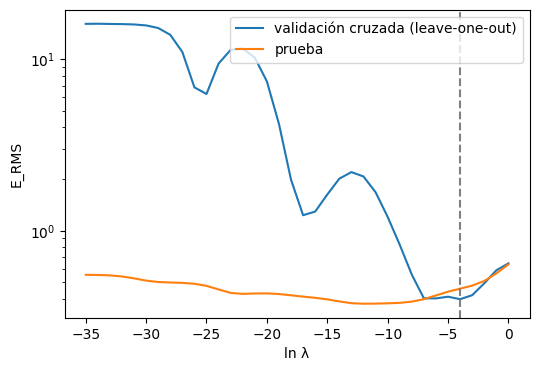

In [9]:
def error_leave_one_out(x, t, M, lam):
    errores = []
    for i in range(len(x)):
        dentro = torch.arange(len(x)) != i
        w = ajustar_regularizado(x[dentro], t[dentro], M, lam)
        errores.append((predecir(x[i:i + 1], w) - t[i]).pow(2).item())
    return math.sqrt(sum(errores) / len(errores))


validacion_l = [error_leave_one_out(x, t, 9, math.exp(ln_lam)) for ln_lam in ln_lambdas]
elegido = int(torch.tensor(validacion_l).argmin())
ln_lam_elegido = ln_lambdas[elegido].item()

w_final = ajustar_regularizado(x, t, 9, math.exp(ln_lam_elegido))
print(f"λ elegido por validación cruzada: ln λ = {ln_lam_elegido:.0f}")
print(f"error de prueba con ese λ:        {e_rms(x_prueba, t_prueba, w_final):.3f}")
print(f"el mejor posible mirando la prueba: {prueba_l[mejor]:.3f}")

plt.figure(figsize=(6, 4))
plt.semilogy(ln_lambdas, validacion_l, label="validación cruzada (leave-one-out)")
plt.semilogy(ln_lambdas, prueba_l, label="prueba")
plt.axvline(ln_lam_elegido, color="gray", linestyle="--")
plt.xlabel("ln λ")
plt.ylabel("E_RMS")
plt.legend()
plt.show()

La validación cruzada eligió más regularización ($\ln\lambda = -4$) que la que daba el menor error de prueba, y su error de prueba es más alto. No es un error de cálculo, y vale la pena entender por qué pasa. Miramos el error de cada uno de los diez ajustes con un λ chico y con el elegido:

In [10]:
def errores_por_punto(x, t, M, lam):
    errores = []
    for i in range(len(x)):
        dentro = torch.arange(len(x)) != i
        w = ajustar_regularizado(x[dentro], t[dentro], M, lam)
        errores.append((predecir(x[i:i + 1], w) - t[i]).pow(2).item())
    return errores


print("punto dejado fuera:  " + "".join(f"{v:7.2f}" for v in x.tolist()))
for ln_lam in [-12, -4]:
    errores = errores_por_punto(x, t, 9, math.exp(ln_lam))
    print(f"ln λ = {ln_lam:3d}  error²:  " + "".join(f"{e:7.2f}" for e in errores))

punto dejado fuera:     0.00   0.11   0.22   0.33   0.44   0.56   0.67   0.78   0.89   1.00
ln λ = -12  error²:     0.70   0.00   0.38   0.79   0.01   0.30   0.02   0.16   1.23  39.13
ln λ =  -4  error²:     0.12   0.00   0.02   0.95   0.00   0.40   0.03   0.05   0.00   0.00


Con $\ln\lambda = -12$ casi todo el error viene del último punto, $x = 1$. Al dejarlo fuera, el polinomio se ajusta con datos en $[0, 0.89]$ y tiene que **extrapolar** hasta 1, y un polinomio de grado 9 poco regularizado se dispara fuera de la zona donde tiene datos. Los puntos de prueba, en cambio, caen todos dentro de $[0, 1]$, donde el modelo final tiene datos a ambos lados. La validación cruzada castiga a los λ chicos más de lo que lo hace la prueba, y termina eligiendo uno más grande.

Dos lecciones. Con 10 puntos cualquier estimación del error es ruidosa, y la validación cruzada no es la excepción. Y aun así es el procedimiento correcto: el 0.374 se consiguió **mirando la prueba**, así que no es una estimación honesta del error en datos nuevos. El error de prueba del λ elegido por validación cruzada sí lo es.

## 9. La misma solución con un optimizador de PyTorch

La forma cerrada existe porque el modelo es lineal en $w$ y la pérdida es cuadrática. Una red neuronal no tiene forma cerrada, y se entrena con un optimizador. Comprobamos que un optimizador de PyTorch llega al mismo mínimo regularizado, escribiendo $\tilde{E}(w)$ tal cual y minimizándola.

Usamos `torch.optim.LBFGS`, un método cuasi-Newton que estima la curvatura a partir de los gradientes de los últimos pasos. Para un problema cuadrático y mal condicionado como este, converge en muchos menos pasos que el descenso de gradiente (por qué el condicionamiento importa se vio en `03-optimalidad`).

In [11]:
M, lam = 9, math.exp(ln_lam_elegido)
Phi = caracteristicas(x, M)
print(f"número de condición de Φ^T Φ:       {torch.linalg.cond(Phi.T @ Phi):.1e}")
print(f"número de condición de Φ^T Φ + λI:  {torch.linalg.cond(Phi.T @ Phi + lam * torch.eye(M + 1)):.1e}")

w = torch.zeros(M + 1, requires_grad=True)
optimizador = torch.optim.LBFGS([w], lr=1, max_iter=500, tolerance_grad=1e-12, tolerance_change=1e-15,
                                history_size=20, line_search_fn="strong_wolfe")


def cierre():
    optimizador.zero_grad()
    perdida = 0.5 * ((Phi @ w - t) ** 2).sum() + 0.5 * lam * (w ** 2).sum()
    perdida.backward()
    return perdida


optimizador.step(cierre)
w_cerrada = ajustar_regularizado(x, t, M, lam)
print(f"\ndiferencia máxima con la forma cerrada: {(w.detach() - w_cerrada).abs().max():.1e}")
print("¿coinciden?", torch.allclose(w.detach(), w_cerrada, atol=1e-6))

número de condición de Φ^T Φ:       2.3e+14
número de condición de Φ^T Φ + λI:  1.1e+03



diferencia máxima con la forma cerrada: 1.8e-07
¿coinciden? True


`LBFGS` necesita un `cierre` (*closure*): una función que recalcula la pérdida y sus gradientes, porque en cada paso evalúa la pérdida varias veces mientras busca el tamaño de paso.

La regularización también ayuda al optimizador: sumar $\lambda I$ baja el número de condición en varios órdenes de magnitud.

## 10. Resumen

- Ajustar un polinomio es una regresión lineal sobre las características $1, x, \dots, x^M$, con solución cerrada en las ecuaciones normales.
- El error de entrenamiento siempre baja al agregar flexibilidad. El de prueba baja y después sube: eso es el **sobreajuste**, un modelo que sigue el ruido de sus datos de entrenamiento.
- Un síntoma del sobreajuste son los coeficientes enormes, que se cancelan entre sí para pasar por cada punto.
- Más datos permiten modelos más flexibles sin sobreajustar.
- La regularización L2 castiga $\lVert w\rVert^2$. Controla la complejidad de forma continua, y λ se elige como el grado: buscando el menor error en datos no vistos.
- Los datos de prueba no se usan para elegir nada. Para elegir hiperparámetros se usa un conjunto de validación o, con pocos datos, validación cruzada.
- Un optimizador de PyTorch (`LBFGS`) llega al mismo mínimo que la forma cerrada.

## Ejercicios

1. Repite la sección 4 con `ruido=0.1` y con `ruido=0.6`. ¿Cambia el grado con menor error de prueba? ¿Por qué tiene sentido?
2. Usa `error_leave_one_out` con `lam` muy chico (por ejemplo `1e-12`) para elegir el grado $M$ entre 0 y 8. ¿Elige el mismo grado que el error de prueba de la sección 4?
3. Bishop menciona que muchas veces el coeficiente $w_0$ se deja fuera de la regularización. Modifica `ajustar_regularizado` para no castigar $w_0$ (pista: en vez de $\lambda I$, usa una matriz identidad con un 0 en la primera posición). ¿Por qué tendría sentido no castigar el término constante?
4. En la sección 9, reemplaza `LBFGS` por `torch.optim.SGD` con `lr=0.01`. ¿Cuántos pasos necesita para acercarse a la forma cerrada? Usa el número de condición para explicarlo.
5. Repite la sección 6 con N = 15 y N = 100, pero con $M = 15$. ¿Con cuántos puntos deja de oscilar?